# How do flipper length and body mass vary across penguin species?
Palmer Archipelago · 2007–2009 · 2323 CIS

We compare typical measurements across species and examine whether the pooled association also appears within each species. Each row represents one observed penguin. Source: Horst, Hill & Gorman, [palmerpenguins](https://allisonhorst.github.io/palmerpenguins/), based on Palmer Station LTER observations.

**Group 2**

| Student | Student ID |
|---|---|
| Waf Ibrahim | 448819208 |
| Fajr Hamadani | 448819210 |
| Noorah Assiri | 448820841 |
| Amjad Abdullah | 448816846 |
| Atheer Ali Alshehri | 448817560 |

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

out = Path("outputs")
out.mkdir(exist_ok=True)
raw = pd.read_csv("data/penguins.csv", na_values=["NA"])
print("Rows and columns:", raw.shape)
print(pd.DataFrame({"type": raw.dtypes, "missing": raw.isna().sum()}))
print(raw.describe().round(2).to_string())
print("Exact duplicate rows:", raw.duplicated().sum())

Rows and columns: (344, 8)
                      type  missing
species             object        0
island              object        0
bill_length_mm     float64        2
bill_depth_mm      float64        2
flipper_length_mm  float64        2
body_mass_g        float64        2
sex                 object       11
year                 int64        0
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g     year
count          342.00         342.00             342.00       342.00   344.00
mean            43.92          17.15             200.92      4201.75  2008.03
std              5.46           1.97              14.06       801.95     0.82
min             32.10          13.10             172.00      2700.00  2007.00
25%             39.22          15.60             190.00      3550.00  2007.00
50%             44.45          17.30             197.00      4050.00  2008.00
75%             48.50          18.70             213.00      4750.00  2009.00
max             59.60    

## Prepare the analysis sample
The question needs a species, a mass and a flipper length. Exclude observations missing these fields and keep rows missing sex because this analysis does not use sex. Positive values are required for length and mass. Convert grams to kilograms for readability, then group by species. Use medians to describe typical birds without assuming symmetric distributions.

In [2]:
fields = ["species", "body_mass_g", "flipper_length_mm"]
data = raw.dropna(subset=fields).copy()
assert (data[["body_mass_g", "flipper_length_mm"]] > 0).all().all()
data["body_mass_kg"] = data["body_mass_g"] / 1000
groups = data.groupby("species")
summary = groups.agg(n=("species","size"), median_mass_kg=("body_mass_kg","median"),
                     median_flipper_mm=("flipper_length_mm","median"))
print(f"Retained {len(data)} of {len(raw)} observations.")
print(summary)
data.to_csv(out / "analysis_ready.csv", index=False)
summary.to_csv(out / "species_summary.csv")
colors = ["#077E83", "#B75C30", "#38549B"]

Retained 342 of 344 observations.
             n  median_mass_kg  median_flipper_mm
species                                          
Adelie     151             3.7              190.0
Chinstrap   68             3.7              196.0
Gentoo     123             5.0              216.0


## 1 · How do typical masses compare?

Gentoo median mass is 5.00 kg, compared with 3.70 kg for Adelie.


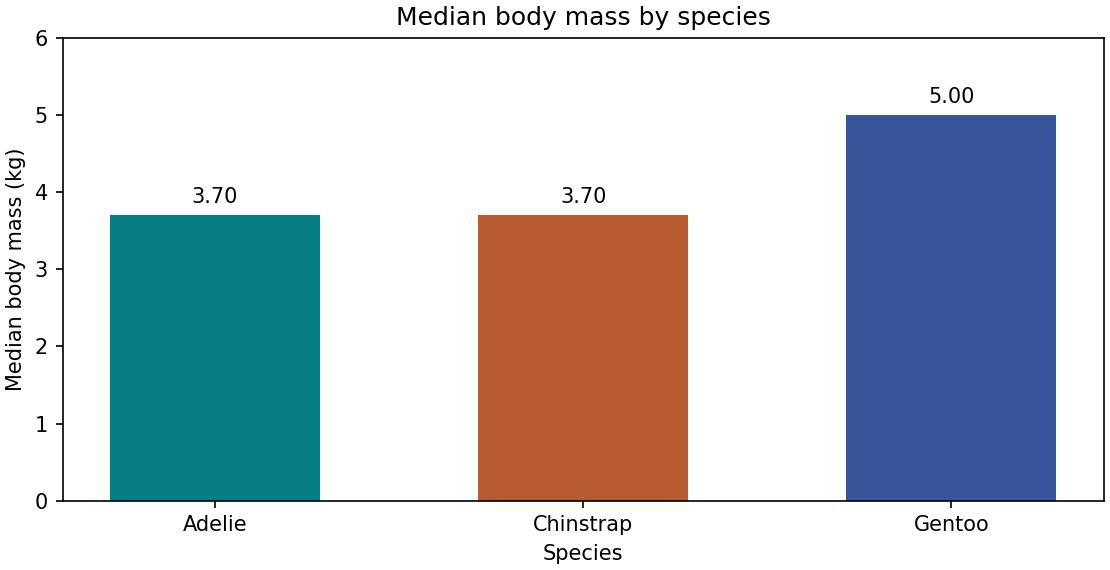

In [3]:
fig, ax = plt.subplots(figsize=(7.4, 3.8), layout="constrained")
bars = ax.bar(summary.index, summary.median_mass_kg, color=colors, width=.57)
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set(xlabel="Species", ylabel="Median body mass (kg)", title="Median body mass by species", ylim=(0,6))
fig.savefig(out / "mass.png", dpi=150)
plt.show()
print(f"Gentoo median mass is {summary.loc['Gentoo','median_mass_kg']:.2f} kg, compared with {summary.loc['Adelie','median_mass_kg']:.2f} kg for Adelie.")

## 2 · How much do flipper lengths overlap?

            0.25   0.50   0.75
species                       
Adelie     186.0  190.0  195.0
Chinstrap  191.0  196.0  201.0
Gentoo     212.0  216.0  221.0
The Gentoo middle 50% lies above the middle 50% of both other species. The Adelie and Chinstrap middle ranges overlap.


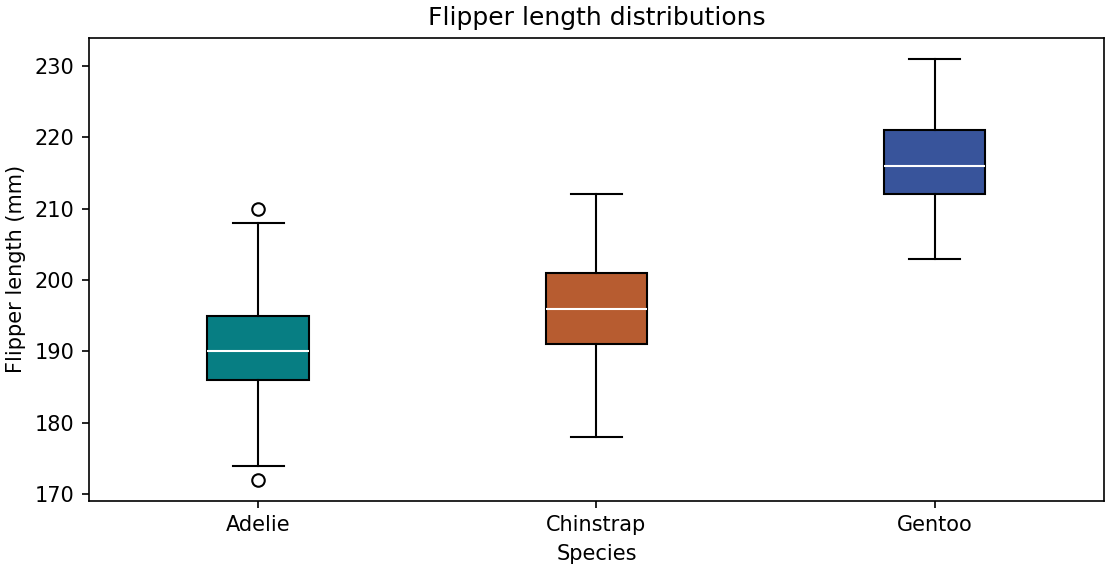

In [4]:
fig, ax = plt.subplots(figsize=(7.4, 3.8), layout="constrained")
boxes = ax.boxplot([g.flipper_length_mm for _, g in groups], patch_artist=True)
for patch, color in zip(boxes["boxes"], colors):
    patch.set_facecolor(color)
for median in boxes["medians"]:
    median.set_color("white")
ax.set_xticks(range(1,len(summary)+1),summary.index)
ax.set(xlabel="Species", ylabel="Flipper length (mm)", title="Flipper length distributions")
fig.savefig(out / "flippers.png", dpi=150)
plt.show()
print(groups.flipper_length_mm.quantile([.25,.5,.75]).unstack())
print("The Gentoo middle 50% lies above the middle 50% of both other species. The Adelie and Chinstrap middle ranges overlap.")

## 3 · Does the mass–length relationship persist within species?

Pooled Pearson r = 0.87.
Adelie: r = 0.47
Chinstrap: r = 0.64
Gentoo: r = 0.70
The positive association persists within every species, but pooling the groups gives a stronger correlation.


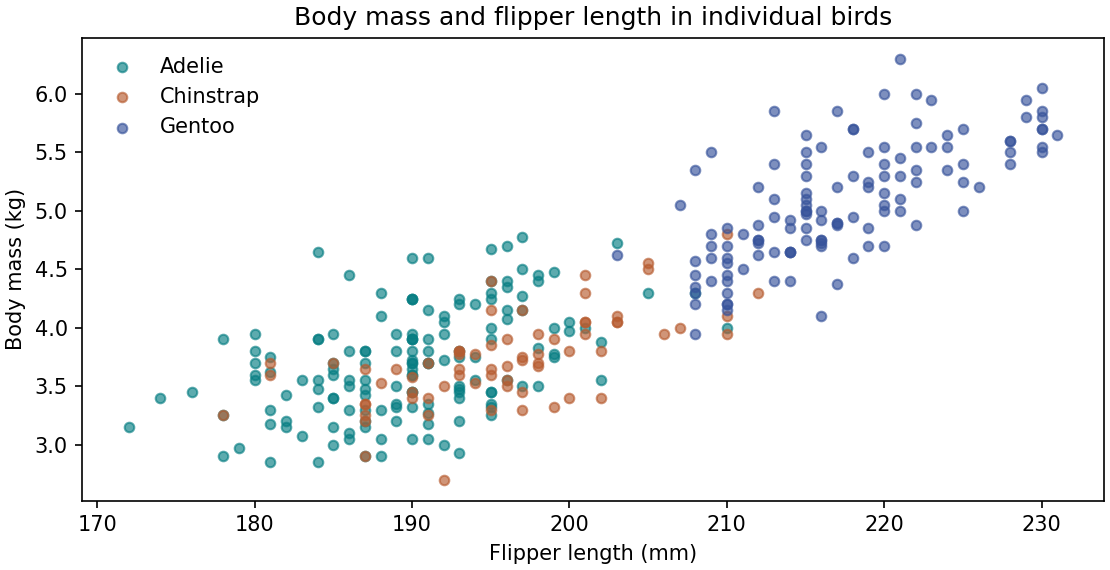

In [5]:
fig, ax = plt.subplots(figsize=(7.4, 3.8), layout="constrained")
for (name, g), color in zip(groups,colors):
    ax.scatter(g.flipper_length_mm, g.body_mass_kg, label=name, c=color, alpha=.65, s=21)
ax.legend(frameon=False)
ax.set(xlabel="Flipper length (mm)", ylabel="Body mass (kg)", title="Body mass and flipper length in individual birds")
fig.savefig(out / "association.png", dpi=150)
plt.show()
r = data.flipper_length_mm.corr(data.body_mass_kg)
within = {name: g.flipper_length_mm.corr(g.body_mass_kg) for name,g in groups}
print(f"Pooled Pearson r = {r:.2f}.")
for name, value in within.items():
    print(f"{name}: r = {value:.2f}")
print("The positive association persists within every species, but pooling the groups gives a stronger correlation.")

## Conclusion and limits
Gentoo has the highest median mass and longest median flippers in this sample. The other species have similar typical masses but different median flipper lengths. Both within-species variation and differences between species are visible in the pooled scatterplot. These descriptive results apply to sampled birds at the study islands during 2007–2009. Sex and island were not adjusted for, and the correlations cannot establish causality.